# Solar-ring age distribution: $dN_{\rm sample}/d\ln t$

Compare `proton_earth_t1e9_D0.5.bin` with the absolutely normalized diffusion prediction. Parameters match `diffusion.cpp`: 10,000 protons injected at the origin, total energies 10–$10^7$ GeV, $\lambda\propto\mathcal R^{1/2}$, and propagation to $10^9$ yr.

Each binary record contains two native-endian float64 values: total proton energy [GeV] and age [yr]. Repeated step endpoints inside the solar ring are recorded, so this is an occupancy-sample distribution, not a first-arrival distribution. Repeated samples from one particle are correlated.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf

file_name = 'proton_earth_t1e9_D0.5.bin'
N_particles = 10000
E_min = 10.0             # total proton energy, GeV
E_max = 1e7              # GeV
delta = 0.5
T_end = 1e9              # yr
R_earth = 8000.0         # pc
c_pc_yr = 0.30660139

file = Path(file_name)
if not file.exists():
    file = Path('age_dist') / file_name

data = np.fromfile(file, dtype='=f8').reshape(-1, 2)
E_arr = data[:, 0]
time_arr = data[:, 1]
print('File:', file)
print('Step samples:', len(data))
print('Recorded age range [yr]:', time_arr.min(), time_arr.max())
print('Recorded total-energy range [GeV]:', E_arr.min(), E_arr.max())

File: proton_earth_t1e9_D0.5.bin
Step samples: 83225
Recorded age range [yr]: 16128.552969375305 996697198.7367806
Recorded total-energy range [GeV]: 10.027672000990757 10000000.00000002


In [7]:
np.min(E_arr)

np.float64(10.027672000990757)

## Diffusion prediction and normalization

The point-source Green function is
$$G(R,t;E)=(4\pi D(E)t)^{-3/2}\exp[-R^2/(4D(E)t)].$$
The solar-ring tube has radius $\lambda$, volume $V=2\pi^2R_\oplus\lambda^2$, and sampling interval $\Delta t=\lambda/(2c)$. Thus $V/\Delta t=12\pi^2R_\oplus D$, where $D=c\lambda/3$.

For $dN_0/dE=C/E$, $D\propto E^\delta$, and $b=R_\oplus^2/4$,
$$F(t)=\frac{dN_{\rm sample}}{d\ln t}
=\frac{3\pi C}{\delta}\left[\operatorname{erf}\sqrt{\frac{b}{D_{\min}t}}-\operatorname{erf}\sqrt{\frac{b}{D_{\max}t}}\right],
\qquad C=\frac{N_{\rm particles}}{\ln(E_{\max}/E_{\min})}.$$

This uses the relativistic approximation $\mathcal R\simeq E$; the C++ code uses $\mathcal R=\sqrt{E^2-m_p^2}$. It also approximates the density as constant across the torus and takes the diffusion limit. The highest-energy tube radius is about 2 kpc, so the thin-torus approximation is less accurate there. The final shortened step is neglected. No fit or arbitrary amplitude scaling is applied.

In [2]:
C = N_particles / np.log(E_max / E_min)
b = R_earth**2 / 4
D_min = c_pc_yr * 2.0 * (E_min / 10.0)**delta / 3
D_max = c_pc_yr * 2.0 * (E_max / 10.0)**delta / 3


def predicted_age(t):
    # erf(x) = 2/sqrt(pi) * integral_0^x exp(-u^2) du.
    # The energy integral of the diffusion solution gives this function;
    # scipy.special.erf evaluates it directly, without fitting the data.
    slow = np.sqrt(b / (D_min * t))
    fast = np.sqrt(b / (D_max * t))
    return 3 * np.pi * C / delta * (erf(slow) - erf(fast))


print('Transition times b/D_max, b/D_min [yr]:', b / D_max, b / D_min)

Transition times b/D_max, b/D_min [yr]: 78277.53161849658 78277531.61849658


In [3]:
# Eight bins per decade; include earlier records if they occur below 1e4 yr.
t_min = min(1e4, time_arr.min() * 0.99)
N_bins = int(np.ceil(8 * np.log10(T_end / t_min)))
time_bins = np.logspace(np.log10(t_min), np.log10(T_end), N_bins + 1)
time_bins[-1] = T_end
time_centers = np.sqrt(time_bins[:-1] * time_bins[1:])
dlnt = np.diff(np.log(time_bins))

counts = np.histogram(time_arr, bins=time_bins)[0]
observed = counts / dlnt

# Integrate F(t) over ln(t) in each bin to obtain expected counts.
# Dividing by the same ln(t) bin width gives the theoretical bin average.
expected_counts = np.zeros(N_bins)
for j in range(N_bins):
    logt = np.linspace(np.log(time_bins[j]), np.log(time_bins[j+1]), 65)
    values = predicted_age(np.exp(logt))
    expected_counts[j] = np.sum((values[1:] + values[:-1]) / 2 * np.diff(logt))
expected = expected_counts / dlnt

print('Observed samples in bins:', counts.sum())
print('Predicted samples in bins:', expected_counts.sum())

Observed samples in bins: 83225
Predicted samples in bins: 85979.31083655453


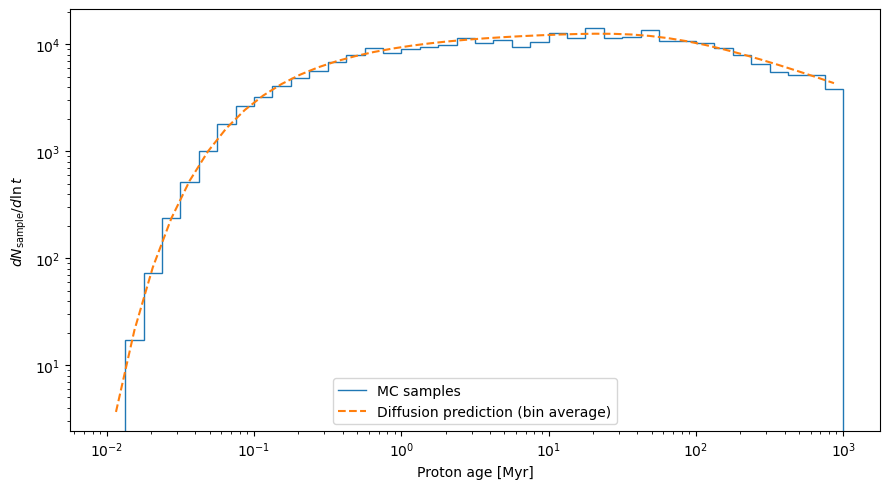

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.stairs(observed, time_bins / 1e6, label='MC samples')
ax.plot(time_centers / 1e6, expected, '--', label='Diffusion prediction (bin average)')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Proton age [Myr]')
ax.set_ylabel(r'$dN_{\rm sample}/d\ln t$')
ax.legend()
fig.tight_layout()
plt.show()

At late times $t\gg b/D_{\min}\simeq7.8\times10^7$ yr, the prediction approaches $F(t)\propto t^{-1/2}$. The finite run ends at $10^9$ yr, where the asymptotic regime is still being approached. Zero-count bins cannot appear on a logarithmic y axis. No independent Poisson error bars are assigned because repeat visits are correlated.